In [31]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

In [32]:
# Paths

DATA_DIR = Path("../data/blogfeedback")
DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DATA_DIR / "blogfeedback.zip"

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/304/blogfeedback.zip"
)

In [33]:
# Download and extract the BlogFeedback dataset

if not ZIP_PATH.exists():
    print("Downloading BlogFeedback dataset...")
    urlretrieve(DATA_URL, ZIP_PATH)
    print("Download completed.")
else:
    print("Dataset archive already downloaded.")

with ZipFile(ZIP_PATH, "r") as zip_file:
    zip_file.extractall(DATA_DIR)

print("Extraction completed.")

Dataset archive already downloaded.
Extraction completed.


In [34]:
files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(files))

for file in files[:10]:
    print(file.name)

Number of CSV files: 61
blogData_test-2012.02.01.00_00.csv
blogData_test-2012.02.02.00_00.csv
blogData_test-2012.02.03.00_00.csv
blogData_test-2012.02.04.00_00.csv
blogData_test-2012.02.05.00_00.csv
blogData_test-2012.02.06.00_00.csv
blogData_test-2012.02.07.00_00.csv
blogData_test-2012.02.08.00_00.csv
blogData_test-2012.02.09.00_00.csv
blogData_test-2012.02.10.00_00.csv


In [35]:
TRAIN_FILE = DATA_DIR / "blogData_train.csv"

test_files = sorted(
    DATA_DIR.glob("blogData_test-*.csv")
)

print("Training file:", TRAIN_FILE.name)
print("Training file exists:", TRAIN_FILE.exists())

print("Number of test files:", len(test_files))
print("First test file:", test_files[0].name)
print("Last test file:", test_files[-1].name)

Training file: blogData_train.csv
Training file exists: True
Number of test files: 60
First test file: blogData_test-2012.02.01.00_00.csv
Last test file: blogData_test-2012.03.31.01_00.csv


In [36]:
# Load the real-world training data

train_data = np.loadtxt(
    TRAIN_FILE,
    delimiter=",",
    dtype=np.float64
)

print("Full training data shape:", train_data.shape)

Full training data shape: (52397, 281)


In [37]:
X_full_real = train_data[:, :-1]
y_full_real = train_data[:, -1]

print("X shape:", X_full_real.shape)
print("y shape:", y_full_real.shape)

X shape: (52397, 280)
y shape: (52397,)


In [38]:
# Load the latest temporally separated test set

TEST_FILE = test_files[-1]

test_data = np.loadtxt(
    TEST_FILE,
    delimiter=",",
    dtype=np.float64
)

X_test_real_full = test_data[:, :-1]
y_test_real = test_data[:, -1]

print("Test file:", TEST_FILE.name)
print("Test data shape:", test_data.shape)
print("X_test shape:", X_test_real_full.shape)
print("y_test shape:", y_test_real.shape)

Test file: blogData_test-2012.03.31.01_00.csv
Test data shape: (214, 281)
X_test shape: (214, 280)
y_test shape: (214,)


In [39]:
print("Training target:")
print("  min:", np.min(y_full_real))
print("  median:", np.median(y_full_real))
print("  mean:", np.mean(y_full_real))
print("  max:", np.max(y_full_real))

print("\nTest target:")
print("  min:", np.min(y_test_real))
print("  median:", np.median(y_test_real))
print("  mean:", np.mean(y_test_real))
print("  max:", np.max(y_test_real))

Training target:
  min: 0.0
  median: 0.0
  mean: 6.764719354161498
  max: 1424.0

Test target:
  min: 0.0
  median: 0.0
  mean: 7.08411214953271
  max: 632.0


In [40]:
# Real-world experiment settings

N_TRAIN_REAL = 150
D_MAX_REAL = X_full_real.shape[1]   # 280

real_rng = np.random.default_rng(RANDOM_SEED)

# Randomly select 150 observations from the official training data
train_indices = real_rng.choice(
    X_full_real.shape[0],
    size=N_TRAIN_REAL,
    replace=False
)

X_train_real_raw = X_full_real[train_indices]
y_train_real_raw = y_full_real[train_indices]

# Log-transform the highly skewed target
y_train_real = np.log1p(y_train_real_raw)
y_test_real_log = np.log1p(y_test_real)

print("Training subset shape:", X_train_real_raw.shape)
print("Transformed y train shape:", y_train_real.shape)

print("\nOriginal target mean:", np.mean(y_train_real_raw))
print("Log-target mean:", np.mean(y_train_real))

Training subset shape: (150, 280)
Transformed y train shape: (150,)

Original target mean: 5.533333333333333
Log-target mean: 0.6197627027871994


In [41]:
# Fixed random ordering of the 280 features

feature_order = real_rng.permutation(D_MAX_REAL)

X_train_real_ordered = X_train_real_raw[:, feature_order]
X_test_real_ordered = X_test_real_full[:, feature_order]

print("First 10 feature indices:", feature_order[:10])

First 10 feature indices: [186  40 254 159 213  51 214 151 100  91]


In [42]:
# Standardization using training statistics only

feature_mean = X_train_real_ordered.mean(axis=0)
feature_std = X_train_real_ordered.std(axis=0)

# Detect constant features
zero_variance = feature_std == 0

print("Zero-variance features:", np.sum(zero_variance))

# Avoid division by zero
feature_std_safe = feature_std.copy()
feature_std_safe[zero_variance] = 1.0

X_train_real_scaled = (
    X_train_real_ordered - feature_mean
) / feature_std_safe

X_test_real_scaled = (
    X_test_real_ordered - feature_mean
) / feature_std_safe

print("Scaled train shape:", X_train_real_scaled.shape)
print("Scaled test shape:", X_test_real_scaled.shape)

Zero-variance features: 108
Scaled train shape: (150, 280)
Scaled test shape: (214, 280)


In [43]:
# Remove features that are constant in the training subset

nonconstant_mask = ~zero_variance

X_train_real_final = X_train_real_scaled[:, nonconstant_mask]
X_test_real_final = X_test_real_scaled[:, nonconstant_mask]

D_EFFECTIVE = X_train_real_final.shape[1]

print("Original number of features:", D_MAX_REAL)
print("Removed zero-variance features:", np.sum(zero_variance))
print("Remaining usable features:", D_EFFECTIVE)

print(
    "Rank of full training matrix:",
    np.linalg.matrix_rank(X_train_real_final)
)

Original number of features: 280
Removed zero-variance features: 108
Remaining usable features: 172
Rank of full training matrix: 143


In [44]:
# Center the target using training information only

y_train_mean = np.mean(y_train_real)

y_train_real_centered = (
    y_train_real - y_train_mean
)

y_test_real_centered = (
    y_test_real_log - y_train_mean
)

print("Training target mean before centering:", y_train_mean)
print(
    "Training target mean after centering:",
    np.mean(y_train_real_centered)
)

Training target mean before centering: 0.6197627027871994
Training target mean after centering: -5.921189464667502e-18


In [45]:
# Study effective dimensionality as the number of features increases

D_VALUES_REAL = np.array([
    10, 20, 40, 60, 80, 100, 120, 130, 140,
    145, 150, 155, 160, 165, 170, 172
])

ranks_real = []

for d in D_VALUES_REAL:
    X_d = X_train_real_final[:, :d]
    ranks_real.append(
        np.linalg.matrix_rank(X_d)
    )

for d, rank in zip(D_VALUES_REAL, ranks_real):
    print(f"d = {d:3d} | rank = {rank:3d}")

d =  10 | rank =  10
d =  20 | rank =  20
d =  40 | rank =  39
d =  60 | rank =  59
d =  80 | rank =  77
d = 100 | rank =  95
d = 120 | rank = 112
d = 130 | rank = 118
d = 140 | rank = 128
d = 145 | rank = 132
d = 150 | rank = 137
d = 155 | rank = 141
d = 160 | rank = 143
d = 165 | rank = 143
d = 170 | rank = 143
d = 172 | rank = 143


In [46]:
def fit_min_norm_least_squares(X, y, tol=1e-10):
    """
    Minimum-norm least squares solution using SVD.
    Works also with rank-deficient matrices.
    """

    U, singular_values, Vt = np.linalg.svd(
        X,
        full_matrices=False
    )

    cutoff = tol * singular_values[0]

    inverse_singular_values = np.where(
        singular_values > cutoff,
        1.0 / singular_values,
        0.0
    )

    w = Vt.T @ (
        inverse_singular_values * (U.T @ y)
    )

    return w


def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [47]:
real_train_errors = []
real_test_errors = []
real_model_ranks = []

for d in D_VALUES_REAL:

    X_train_d = X_train_real_final[:, :d]
    X_test_d = X_test_real_final[:, :d]

    # Effective rank
    rank_d = np.linalg.matrix_rank(X_train_d)
    real_model_ranks.append(rank_d)

    # Fit minimum-norm least squares
    w_hat = fit_min_norm_least_squares(
        X_train_d,
        y_train_real_centered
    )

    # Predictions
    train_pred = X_train_d @ w_hat
    test_pred = X_test_d @ w_hat

    # Errors
    real_train_errors.append(
        mean_squared_error(
            y_train_real_centered,
            train_pred
        )
    )

    real_test_errors.append(
        mean_squared_error(
            y_test_real_centered,
            test_pred
        )
    )

real_train_errors = np.array(real_train_errors)
real_test_errors = np.array(real_test_errors)

print("Real-world Least Squares experiment completed.")

Real-world Least Squares experiment completed.


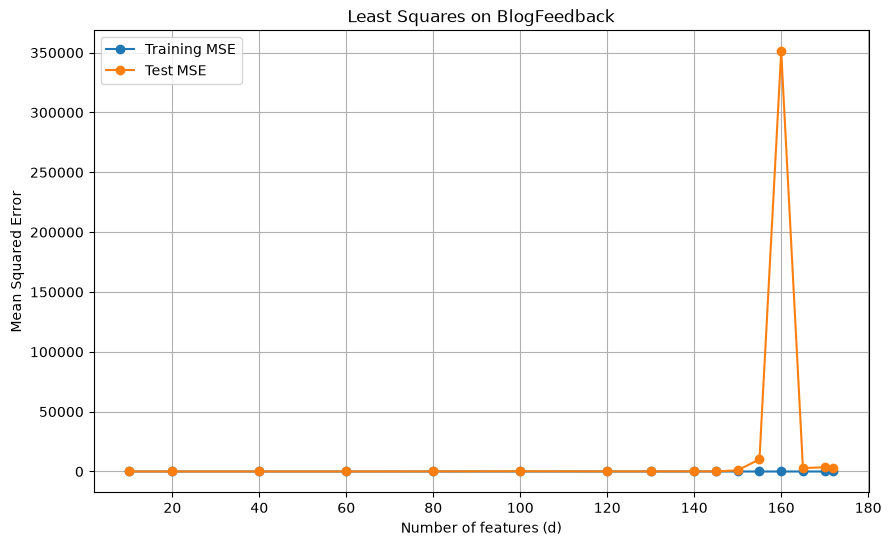

In [48]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REAL,
    real_train_errors,
    marker="o",
    label="Training MSE"
)

plt.plot(
    D_VALUES_REAL,
    real_test_errors,
    marker="o",
    label="Test MSE"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title("Least Squares on BlogFeedback")

plt.legend()
plt.grid(True)

plt.show()

In [49]:
# Diagnose instability of the real-world least squares models

print(
    f"{'d':>5} "
    f"{'rank':>6} "
    f"{'train MSE':>12} "
    f"{'test MSE':>14} "
    f"{'||w||':>12} "
    f"{'min singular':>15}"
)

for d in D_VALUES_REAL:

    X_train_d = X_train_real_final[:, :d]
    X_test_d = X_test_real_final[:, :d]

    U, singular_values, Vt = np.linalg.svd(
        X_train_d,
        full_matrices=False
    )

    w_hat = fit_min_norm_least_squares(
        X_train_d,
        y_train_real_centered
    )

    train_pred = X_train_d @ w_hat
    test_pred = X_test_d @ w_hat

    rank_d = np.linalg.matrix_rank(X_train_d)

    print(
        f"{d:5d} "
        f"{rank_d:6d} "
        f"{mean_squared_error(y_train_real_centered, train_pred):12.4f} "
        f"{mean_squared_error(y_test_real_centered, test_pred):14.4f} "
        f"{np.linalg.norm(w_hat):12.4f} "
        f"{singular_values[rank_d - 1]:15.6e}"
    )

    d   rank    train MSE       test MSE        ||w||    min singular
   10     10       0.7022         1.0110       0.6772    4.862186e+00
   20     20       0.6211         1.1371       2.1773    5.652441e-01
   40     39       0.4849         2.3717      14.5289    1.116608e-01
   60     59       0.3416         5.2066      17.9282    7.486191e-02
   80     77       0.2448        70.9796      26.0757    5.141024e-02
  100     95       0.1425       173.5057      42.2791    2.122412e-02
  120    112       0.0494        72.9316      78.5654    7.502432e-03
  130    118       0.0366        78.9266 14438767.8713    1.784012e-08
  140    128       0.0260        98.4715 25013472.3014    8.833939e-09
  145    132       0.0149        78.5242 22357957.9597    6.667823e-09
  150    137       0.0118       978.8143     327.6422    3.714136e-09
  155    141       0.0077     10198.4366     393.6987    7.881700e-10
  160    143       0.0019    350971.9292    2337.3388    8.938862e-05
  165    143     

In [50]:
def fit_ridge_regression(X, y, alpha):
    """
    Ridge Regression from scratch.
    """

    d = X.shape[1]

    regularized_matrix = (
        X.T @ X
        + alpha * np.eye(d)
    )

    right_hand_side = X.T @ y

    w = np.linalg.solve(
        regularized_matrix,
        right_hand_side
    )

    return w

In [51]:
RIDGE_ALPHA_REAL = 1.0

real_ridge_train_errors = []
real_ridge_test_errors = []

for d in D_VALUES_REAL:

    X_train_d = X_train_real_final[:, :d]
    X_test_d = X_test_real_final[:, :d]

    w_ridge = fit_ridge_regression(
        X_train_d,
        y_train_real_centered,
        alpha=RIDGE_ALPHA_REAL
    )

    train_pred = X_train_d @ w_ridge
    test_pred = X_test_d @ w_ridge

    real_ridge_train_errors.append(
        mean_squared_error(
            y_train_real_centered,
            train_pred
        )
    )

    real_ridge_test_errors.append(
        mean_squared_error(
            y_test_real_centered,
            test_pred
        )
    )

real_ridge_train_errors = np.array(real_ridge_train_errors)
real_ridge_test_errors = np.array(real_ridge_test_errors)

print("Real-world Ridge experiment completed.")

Real-world Ridge experiment completed.


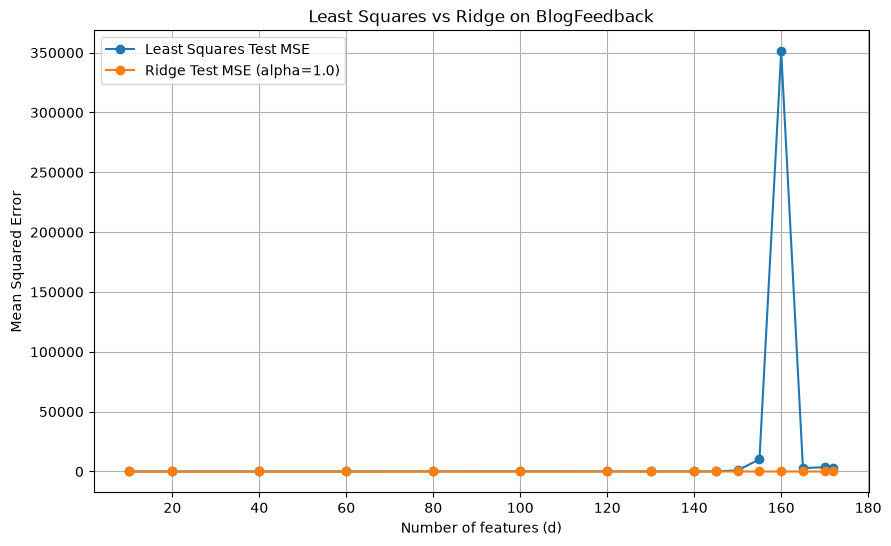

In [52]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REAL,
    real_test_errors,
    marker="o",
    label="Least Squares Test MSE"
)

plt.plot(
    D_VALUES_REAL,
    real_ridge_test_errors,
    marker="o",
    label=f"Ridge Test MSE (alpha={RIDGE_ALPHA_REAL})"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title("Least Squares vs Ridge on BlogFeedback")

plt.legend()
plt.grid(True)

plt.show()

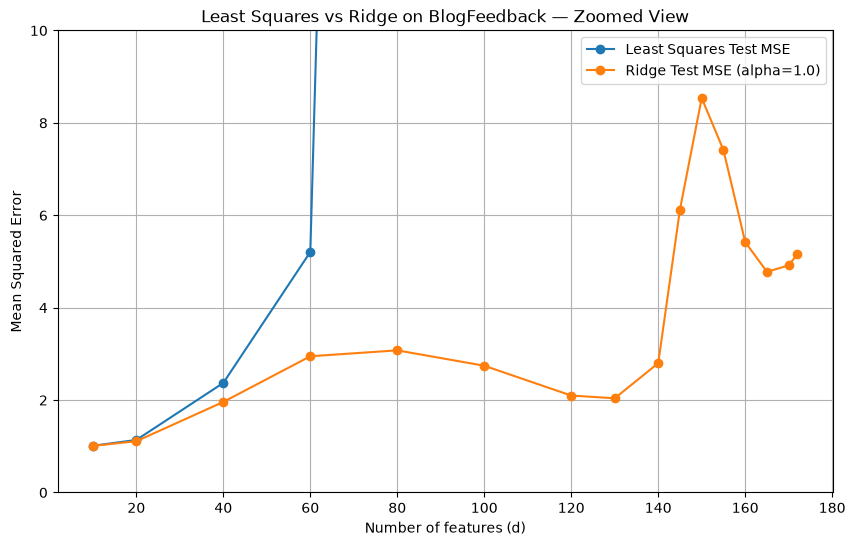

In [53]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REAL,
    real_test_errors,
    marker="o",
    label="Least Squares Test MSE"
)

plt.plot(
    D_VALUES_REAL,
    real_ridge_test_errors,
    marker="o",
    label=f"Ridge Test MSE (alpha={RIDGE_ALPHA_REAL})"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Mean Squared Error")
plt.title("Least Squares vs Ridge on BlogFeedback — Zoomed View")

plt.ylim(0, 10)

plt.legend()
plt.grid(True)

plt.show()

In [54]:
D_VALUES_REPEAT = np.array([
    10, 20, 40, 60, 80, 100,
    120, 130, 140, 145, 150
])

def run_real_world_experiment(seed, alpha=1.0):

    local_rng = np.random.default_rng(seed)

    # 1. Random training subset
    indices = local_rng.choice(
        X_full_real.shape[0],
        size=N_TRAIN_REAL,
        replace=False
    )

    X_train_raw = X_full_real[indices]
    y_train_raw = y_full_real[indices]

    # 2. Log-transform target
    y_train_log = np.log1p(y_train_raw)

    # 3. Random feature ordering
    feature_order = local_rng.permutation(
        X_train_raw.shape[1]
    )

    X_train = X_train_raw[:, feature_order]
    X_test = X_test_real_full[:, feature_order]

    # 4. Standardize using training data only
    feature_mean = X_train.mean(axis=0)
    feature_std = X_train.std(axis=0)

    nonconstant = feature_std > 0

    X_train = X_train[:, nonconstant]
    X_test = X_test[:, nonconstant]

    feature_mean = feature_mean[nonconstant]
    feature_std = feature_std[nonconstant]

    X_train = (
        X_train - feature_mean
    ) / feature_std

    X_test = (
        X_test - feature_mean
    ) / feature_std

    # 5. Center target using training information only
    target_mean = y_train_log.mean()

    y_train = y_train_log - target_mean
    y_test = y_test_real_log - target_mean

    least_squares_errors = []
    ridge_errors = []

    for d in D_VALUES_REPEAT:

        # If this particular subset has too few usable features
        if d > X_train.shape[1]:
            least_squares_errors.append(np.nan)
            ridge_errors.append(np.nan)
            continue

        Xtr = X_train[:, :d]
        Xte = X_test[:, :d]

        # Least Squares
        w_ls = fit_min_norm_least_squares(
            Xtr,
            y_train
        )

        ls_pred = Xte @ w_ls

        least_squares_errors.append(
            mean_squared_error(
                y_test,
                ls_pred
            )
        )

        # Ridge
        w_ridge = fit_ridge_regression(
            Xtr,
            y_train,
            alpha=alpha
        )

        ridge_pred = Xte @ w_ridge

        ridge_errors.append(
            mean_squared_error(
                y_test,
                ridge_pred
            )
        )

    return (
        np.array(least_squares_errors),
        np.array(ridge_errors)
    )

In [55]:
N_REAL_REPETITIONS = 20

all_real_ls = []
all_real_ridge = []

for seed in range(N_REAL_REPETITIONS):

    ls_errors, ridge_errors = (
        run_real_world_experiment(
            seed,
            alpha=1.0
        )
    )

    all_real_ls.append(ls_errors)
    all_real_ridge.append(ridge_errors)

all_real_ls = np.array(all_real_ls)
all_real_ridge = np.array(all_real_ridge)

mean_real_ls = np.nanmean(
    all_real_ls,
    axis=0
)

mean_real_ridge = np.nanmean(
    all_real_ridge,
    axis=0
)

median_real_ls = np.nanmedian(
    all_real_ls,
    axis=0
)

median_real_ridge = np.nanmedian(
    all_real_ridge,
    axis=0
)

print("Repeated real-world experiment completed.")
print("Least Squares results shape:", all_real_ls.shape)
print("Ridge results shape:", all_real_ridge.shape)

Repeated real-world experiment completed.
Least Squares results shape: (20, 11)
Ridge results shape: (20, 11)


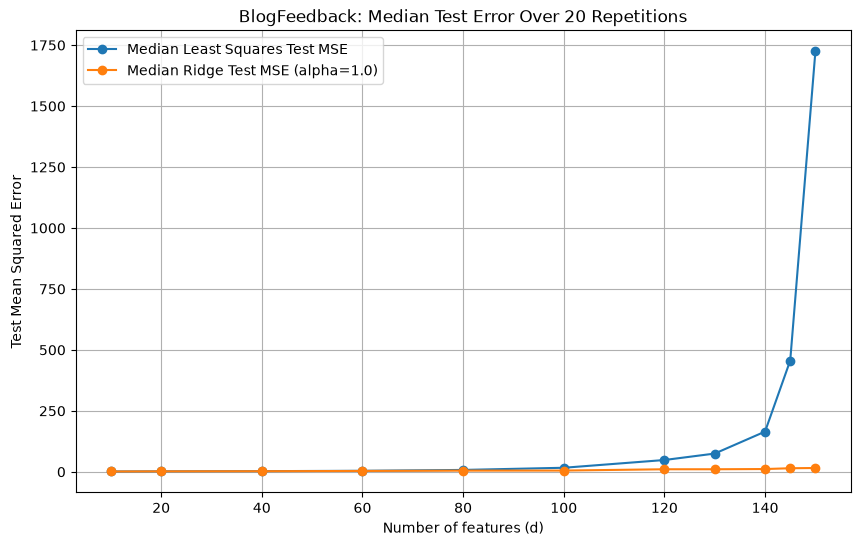

In [56]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REPEAT,
    median_real_ls,
    marker="o",
    label="Median Least Squares Test MSE"
)

plt.plot(
    D_VALUES_REPEAT,
    median_real_ridge,
    marker="o",
    label="Median Ridge Test MSE (alpha=1.0)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Test Mean Squared Error")

plt.title(
    f"BlogFeedback: Median Test Error Over {N_REAL_REPETITIONS} Repetitions"
)

plt.legend()
plt.grid(True)

plt.show()

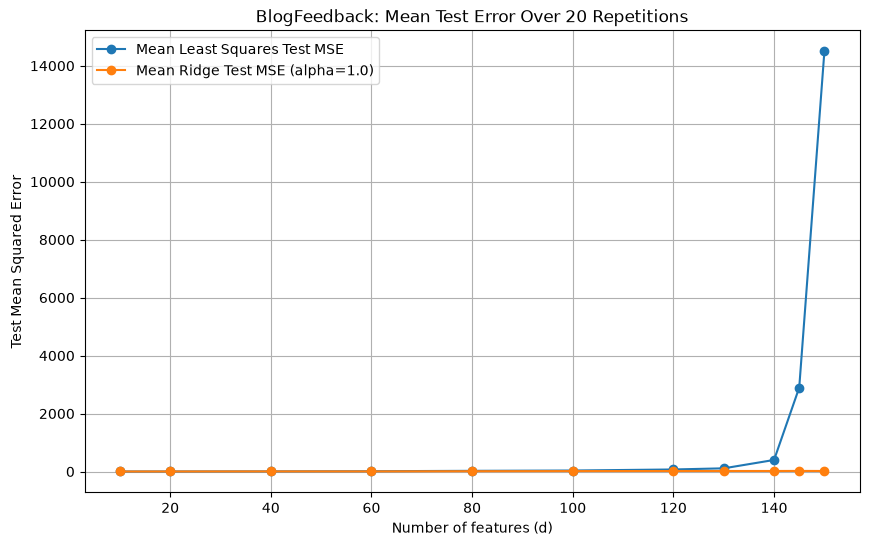

In [57]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REPEAT,
    mean_real_ls,
    marker="o",
    label="Mean Least Squares Test MSE"
)

plt.plot(
    D_VALUES_REPEAT,
    mean_real_ridge,
    marker="o",
    label="Mean Ridge Test MSE (alpha=1.0)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Test Mean Squared Error")

plt.title(
    f"BlogFeedback: Mean Test Error Over {N_REAL_REPETITIONS} Repetitions"
)

plt.legend()
plt.grid(True)

plt.show()

In [63]:
def run_noise_experiment(
    noise_std,
    n_train=150,
    n_test=1000,
    d_max=400,
    d_values=None,
    seed=42
):
    """
    Run the synthetic double-descent experiment
    for a given noise level.
    """

    if d_values is None:
        d_values = np.array([
            10, 20, 40, 60, 80, 100, 120, 130, 140,
            145, 148, 149, 150, 151, 152, 155, 160,
            170, 180, 200, 250, 300, 350, 400
        ])

    local_rng = np.random.default_rng(seed)

    # Generate features
    X_train = local_rng.normal(
        size=(n_train, d_max)
    )

    X_test = local_rng.normal(
        size=(n_test, d_max)
    )

    # Generate true coefficients
    feature_index = np.arange(d_max)

    signs = local_rng.choice(
        [-1.0, 1.0],
        size=d_max
    )

    beta = signs * np.exp(
        -0.02 * feature_index
    )

    beta = beta / np.linalg.norm(beta)

    # Generate labels
    y_train_local = (
        X_train @ beta
        + local_rng.normal(
            scale=noise_std,
            size=n_train
        )
    )

    y_test_local = (
        X_test @ beta
        + local_rng.normal(
            scale=noise_std,
            size=n_test
        )
    )

    test_errors_local = []

    for d in d_values:

        Xtr = X_train[:, :d]
        Xte = X_test[:, :d]

        w_hat = fit_min_norm_least_squares(
            Xtr,
            y_train_local
        )

        predictions = Xte @ w_hat

        test_errors_local.append(
            mean_squared_error(
                y_test_local,
                predictions
            )
        )

    return np.array(test_errors_local)

In [64]:
NOISE_LEVELS = [0.1, 0.5, 1.0]

noise_results = {}

for noise in NOISE_LEVELS:
    noise_results[noise] = run_noise_experiment(
        noise_std=noise,
        seed=42
    )

print("Noise experiments completed.")

Noise experiments completed.


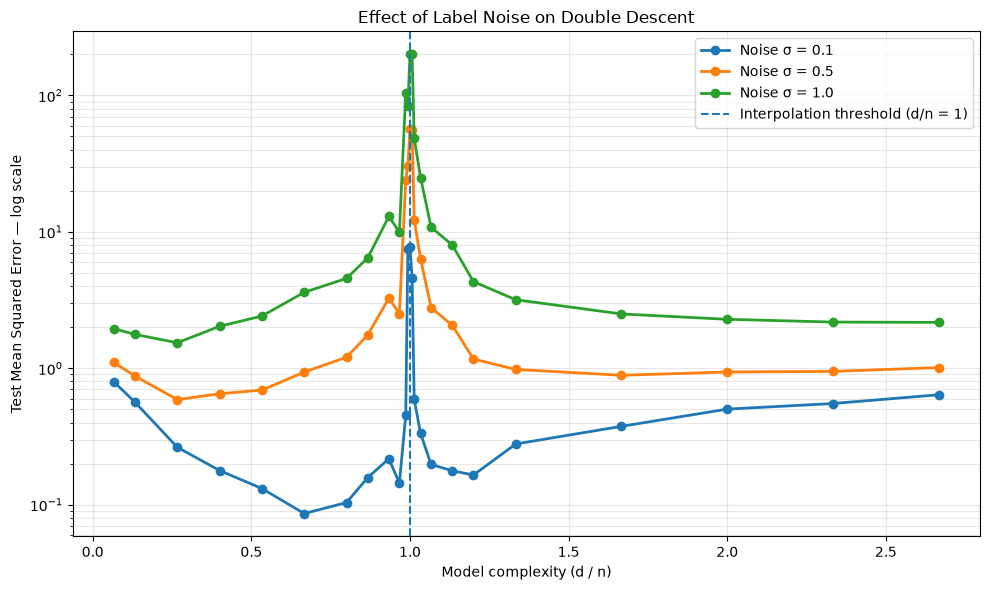

In [66]:
# Better visualization: model complexity as d/n + logarithmic y-axis

D_VALUES_NOISE = np.array([
    10, 20, 40, 60, 80, 100, 120, 130, 140,
    145, 148, 149, 150, 151, 152, 155, 160,
    170, 180, 200, 250, 300, 350, 400
])

N_TRAIN_NOISE = 150

complexity_ratio = D_VALUES_NOISE / N_TRAIN_NOISE

plt.figure(figsize=(10, 6))

for noise in NOISE_LEVELS:
    plt.plot(
        complexity_ratio,
        noise_results[noise],
        marker="o",
        linewidth=2,
        label=f"Noise σ = {noise}"
    )

# Interpolation threshold: d / n = 1
plt.axvline(
    x=1.0,
    linestyle="--",
    label="Interpolation threshold (d/n = 1)"
)

# Logarithmic scale
plt.yscale("log")

plt.xlabel("Model complexity (d / n)")
plt.ylabel("Test Mean Squared Error — log scale")

plt.title("Effect of Label Noise on Double Descent")

plt.legend()
plt.grid(
    True,
    which="both",
    alpha=0.3
)

plt.tight_layout()
plt.show()